# Feature Matching Between Two Images

## Computer Vision Mini-Project

### ORB / SIFT + BFMatcher

**Objective:**  
Detect and match common features between two images using ORB and SIFT feature detection methods, combined with the Brute-Force Matcher (BFMatcher).

### Project Workflow

1. Setup and understand the required concepts
2. Implement the ORB feature-matching pipeline
3. Implement the SIFT feature-matching pipeline
4. Compare ORB and SIFT using multiple image pairs
5. Analyze the results and document the observations
6. Review the complete notebook and prepare it for submission

**Environment:** Google Colab  
**Main Library:** OpenCV

In [ ]:
# Install OpenCV with additional/contrib modules, including SIFT
!pip install -q opencv-contrib-python

## 1.1 Importing and Verifying Required Libraries

In this cell, we import the libraries required for the project.

- **OpenCV (`cv2`)** is used for image processing, ORB, SIFT, BFMatcher, and feature visualization.
- **NumPy** is used for numerical operations and image arrays.
- **Matplotlib** is used to display images and matching results.
- **time** will be used later to compare the execution time of ORB and SIFT.

We also verify that SIFT is available in our OpenCV installation.

In [ ]:
# Import required libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

# Display installed versions
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

# Verify that SIFT is available
sift = cv2.SIFT_create()
print("SIFT is available: Yes")

OpenCV version: 4.14.0
NumPy version: 2.1.3
SIFT is available: Yes


## 1.2 Loading the Input Images

Feature matching requires two images. In this project, we will compare the visual features of **Image 1** with those of **Image 2**.

For our first experiment, the two images should have some common content, such as the same object or scene viewed from a different angle.

We will use Google Colab's `files.upload()` function so that images can be uploaded directly from the computer.

OpenCV loads color images in **BGR (Blue-Green-Red)** format, while Matplotlib expects images in **RGB (Red-Green-Blue)** format. Therefore, after loading the images, we will convert them from BGR to RGB for correct visualization.

The original OpenCV images will be kept unchanged for the feature-matching pipeline.

In [ ]:
from google.colab import files

# Upload two images
uploaded = files.upload()

# Get the uploaded filenames
image_names = list(uploaded.keys())

# Make sure exactly two images are available for this experiment
if len(image_names) != 2:
    raise ValueError("Please upload exactly two images.")

image1_path = image_names[0]
image2_path = image_names[1]

# Load the images using OpenCV
image1 = cv2.imread(image1_path)
image2 = cv2.imread(image2_path)

# Check whether the images were loaded successfully
if image1 is None or image2 is None:
    raise ValueError("One or both images could not be loaded.")

# Convert BGR images to RGB for displaying with Matplotlib
image1_rgb = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2_rgb = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

print("Image 1:", image1_path)
print("Image 2:", image2_path)
print("Images loaded successfully.")

Saving pair1.1.jpeg to pair1.1.jpeg
Saving pair1.2.jpeg to pair1.2.jpeg
Image 1: pair1.1.jpeg
Image 2: pair1.2.jpeg
Images loaded successfully.


## 1.3 Visualizing the First Image Pair

Before detecting features, it is useful to visually inspect the two images that will be compared.

For our first experiment, we use **Pair 1**, which contains the same book photographed from significantly different orientations and viewpoints.

This type of variation is useful for testing whether feature-matching algorithms can identify corresponding parts of an object even when their position and orientation change.

At this stage, we are only displaying the images. Feature detection and matching will be performed in the ORB and SIFT sections.

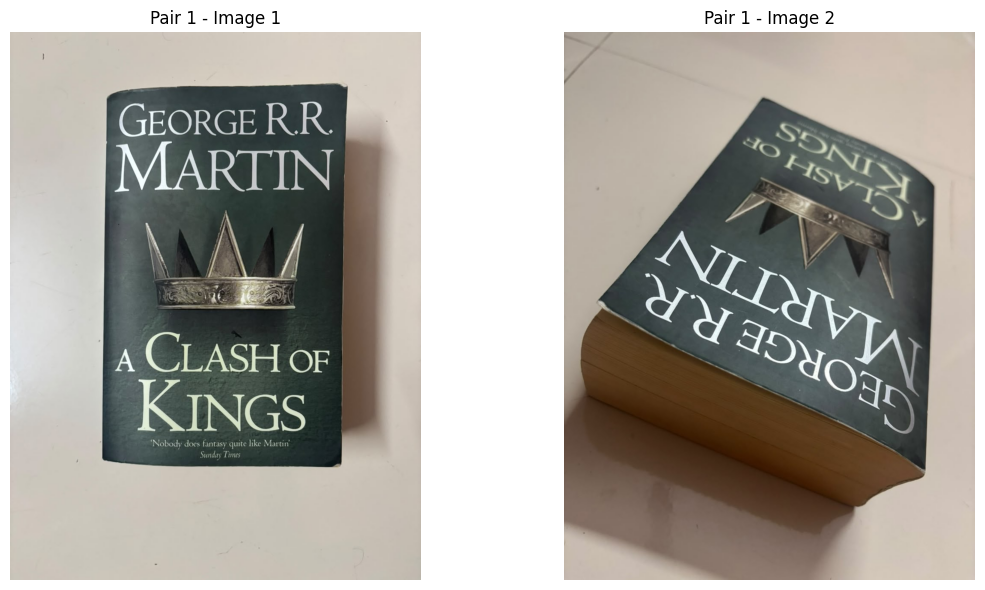

In [ ]:
# Load Pair 1
image1 = cv2.imread("/content/pair1.1.jpeg")
image2 = cv2.imread("/content/pair1.2.jpeg")

# Check that both images were loaded successfully
if image1 is None or image2 is None:
    raise ValueError("Could not load Pair 1. Check the image filenames and paths.")

# Convert BGR to RGB for correct Matplotlib display
image1_rgb = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2_rgb = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

# Display the two images side by side
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image1_rgb)
plt.title("Pair 1 - Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image2_rgb)
plt.title("Pair 1 - Image 2")
plt.axis("off")

plt.tight_layout()
plt.show()

## 2. Understanding Features: Keypoints and Descriptors

Feature matching does not compare the two complete images pixel-by-pixel. Instead, it looks for distinctive local regions called **features**.

### Keypoint

A **keypoint** is an interesting or distinctive location in an image.

Examples include:
- corners of objects,
- intersections of edges,
- distinctive patterns,
- regions with noticeable texture.

For our book images, possible keypoints could occur around:
- corners and edges of letters,
- detailed parts of the crown,
- intersections in the text,
- small patterns and textures on the book cover.

The keypoint tells us **where an interesting feature is located**.

### Descriptor

Finding the location of a feature is not enough. We also need a way to describe what that feature looks like.

A **descriptor** is a numerical representation of the local image region around a keypoint.

It allows us to answer:

> "Does this feature in Image 1 look similar to a feature in Image 2?"

The overall process is therefore:

**Image → Detect Keypoints → Compute Descriptors → Match Descriptors**

ORB and SIFT both follow this general idea, but they create descriptors differently.

## 2.1 Descriptor Matching and Distance Measures

After keypoints are detected and descriptors are created, we need to compare the descriptors from Image 1 with those from Image 2.

The **Brute-Force Matcher (BFMatcher)** does this by comparing descriptors and finding the closest matches.

The meaning of "closest" depends on the type of descriptor.

### ORB → Hamming Distance

ORB produces **binary descriptors**, which are made up of binary values (0s and 1s).

For binary descriptors, we use **Hamming distance**.

Hamming distance measures how many corresponding bits are different between two binary descriptors.

For example:

Descriptor A: `101101`  
Descriptor B: `100001`

The Hamming distance is the number of positions where the bits differ.

Therefore, ORB uses:

`cv2.NORM_HAMMING`

### SIFT → L2 Distance

SIFT produces **floating-point descriptors** rather than binary descriptors.

For these numerical descriptors, we use **L2 distance**, also known as Euclidean distance.

It measures the straight-line distance between two descriptor vectors.

Therefore, SIFT uses:

`cv2.NORM_L2`

### Summary

| Method | Descriptor | Distance used |
|---|---|---|
| ORB | Binary | Hamming |
| SIFT | Floating-point | L2 |

The distance tells us how similar two descriptors are. A **smaller distance generally means the descriptors are more similar**.

## 2.2 Brute-Force Matcher (BFMatcher)

Once ORB or SIFT has detected keypoints and calculated their descriptors, we need to find which features in Image 1 correspond to features in Image 2.

OpenCV provides the **Brute-Force Matcher (`BFMatcher`)** for this purpose.

The matcher compares a descriptor from the first image against descriptors from the second image and finds the closest one based on the selected distance measure.

For our project:

- **ORB → BFMatcher + Hamming distance**
- **SIFT → BFMatcher + L2 distance**

### ORB and `crossCheck=True`

For the ORB pipeline, we will use:

`crossCheck=True`

This makes the matching more selective. A match is accepted only when the best match is consistent in both directions:

**Image 1 feature → Image 2 feature**

and

**Image 2 feature → Image 1 feature**

This helps remove some unreliable matches.

After matching, each match has a **distance value**. A smaller distance means that the two descriptors are more similar.

We will sort the ORB matches by distance and use the best matches for visualization.

## 3. ORB Feature Detection

**ORB (Oriented FAST and Rotated BRIEF)** is a feature detection and description method designed to be fast and efficient.

The first step in the ORB pipeline is to detect **keypoints** in both images.

A keypoint represents a distinctive location in an image that can potentially be matched with a corresponding feature in another image.

We create an ORB detector using `cv2.ORB_create()`.

The `nfeatures` parameter specifies the maximum number of features we want ORB to retain. Here, we use 1000 so that enough features are available for matching while keeping the computation manageable.

At this stage, ORB is only detecting keypoints. We will compute their descriptors in the same operation using `detectAndCompute()`.

In [ ]:
# Import required libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# Display installed versions
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

# Verify that SIFT is available
sift = cv2.SIFT_create()
print("SIFT is available: Yes")

OpenCV version: 4.14.0
NumPy version: 2.1.3
Pandas version: 2.2.3
SIFT is available: Yes


## 3.1 Visualizing Detected ORB Keypoints

ORB has now detected keypoints in both images.

Before matching these features, we can visualize their locations to understand what ORB considers distinctive.

Each small marker represents a detected **keypoint**.

The keypoints are not manually selected by us. ORB automatically searches the image for visually distinctive regions.

In our book images, we expect many keypoints around areas containing:
- text and letters,
- edges and corners,
- the crown and its details,
- patterns and textured regions.

Visualizing keypoints helps us confirm that ORB is detecting features across different parts of the images rather than focusing on only one location.

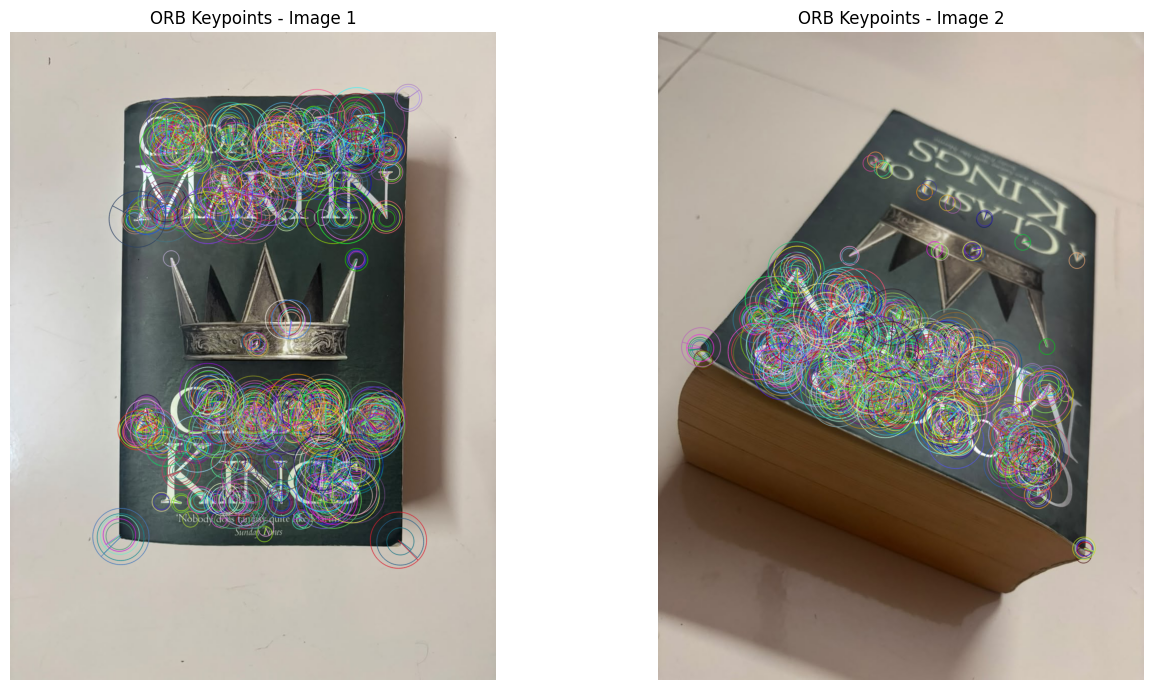

In [ ]:
# Draw the detected ORB keypoints on both images
orb_keypoints_image1 = cv2.drawKeypoints(
    image1,
    orb_keypoints1,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

orb_keypoints_image2 = cv2.drawKeypoints(
    image2,
    orb_keypoints2,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Convert BGR to RGB for Matplotlib
orb_keypoints_image1_rgb = cv2.cvtColor(
    orb_keypoints_image1,
    cv2.COLOR_BGR2RGB
)

orb_keypoints_image2_rgb = cv2.cvtColor(
    orb_keypoints_image2,
    cv2.COLOR_BGR2RGB
)

# Display keypoints side by side
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(orb_keypoints_image1_rgb)
plt.title("ORB Keypoints - Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(orb_keypoints_image2_rgb)
plt.title("ORB Keypoints - Image 2")
plt.axis("off")

plt.tight_layout()
plt.show()

## 3.2 Matching ORB Descriptors Using BFMatcher

ORB has detected keypoints and computed a binary descriptor for each keypoint.

We now need to find corresponding features between the two images.

For this, we use OpenCV's **Brute-Force Matcher (`BFMatcher`)**.

Since ORB produces binary descriptors, we use **Hamming distance**:

`cv2.NORM_HAMMING`

We also set:

`crossCheck=True`

With cross-checking enabled, a match is accepted only when the best match is consistent in both directions. This helps reduce some unreliable correspondences.

After matching, each match has a `distance` value. A smaller distance means that the two binary descriptors are more similar.

Finally, we sort the matches by distance so that the strongest matches appear first.

In [ ]:
# Create a Brute-Force Matcher for ORB
bf_orb = cv2.BFMatcher(
    cv2.NORM_HAMMING,
    crossCheck=True
)

# Match ORB descriptors between the two images
orb_matches = bf_orb.match(
    orb_descriptors1,
    orb_descriptors2
)

# Sort matches by increasing distance
orb_matches = sorted(
    orb_matches,
    key=lambda match: match.distance
)

# Display basic matching information
print("Total ORB matches:", len(orb_matches))
print("Best ORB match distance:", orb_matches[0].distance)

Total ORB matches: 274
Best ORB match distance: 17.0


## 3.3 Visualizing ORB Feature Matches

The BFMatcher has now produced 274 ORB matches.

However, displaying all 274 matches would make the visualization difficult to read. Instead, we sort the matches by descriptor distance and display only the **top 30 matches**.

The matches with the smallest Hamming distances are considered the strongest matches according to the descriptor similarity.

`cv2.drawMatches()` draws a line between the corresponding keypoints in the two images.

Each line therefore represents a proposed correspondence between a feature in Image 1 and a feature in Image 2.

At this stage, we are mainly interested in visually checking whether the strongest matches connect corresponding parts of the same book.

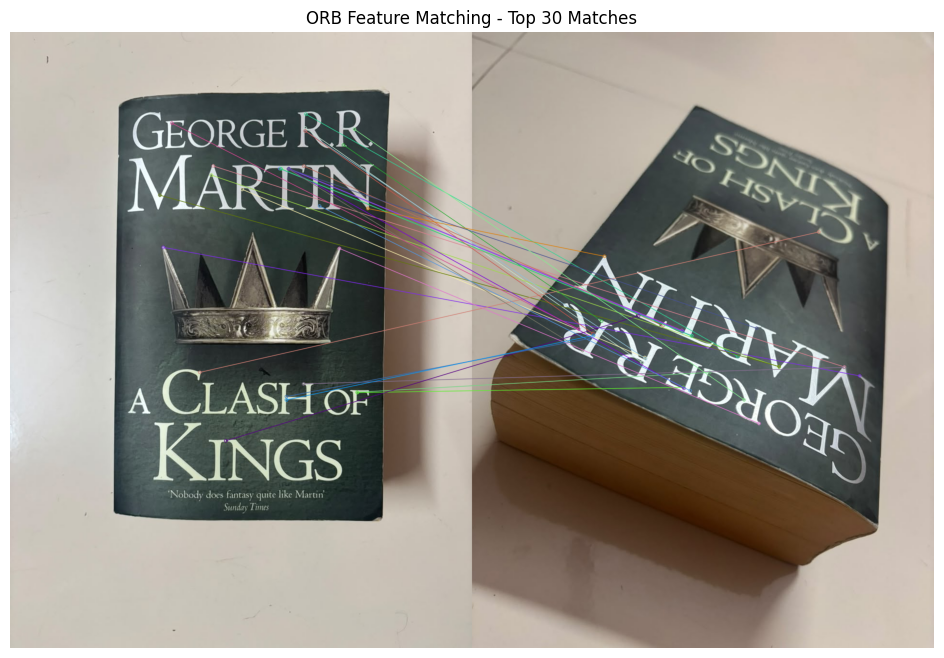

In [ ]:
# Select the 30 best ORB matches
top_orb_matches = orb_matches[:30]

# Draw the top ORB matches
orb_match_image = cv2.drawMatches(
    image1,
    orb_keypoints1,
    image2,
    orb_keypoints2,
    top_orb_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Convert BGR to RGB for Matplotlib
orb_match_image_rgb = cv2.cvtColor(
    orb_match_image,
    cv2.COLOR_BGR2RGB
)

# Display the matches
plt.figure(figsize=(18, 8))
plt.imshow(orb_match_image_rgb)
plt.title("ORB Feature Matching - Top 30 Matches")
plt.axis("off")
plt.show()

## 4. Understanding SIFT Matching and Lowe's Ratio Test

**SIFT (Scale-Invariant Feature Transform)** detects distinctive keypoints and creates a numerical descriptor for each keypoint.

Unlike ORB, SIFT produces **floating-point descriptors**. Therefore, we use **L2 (Euclidean) distance** when comparing SIFT descriptors.

### Why do we need Lowe's Ratio Test?

When BFMatcher finds a match for a SIFT descriptor, there may be more than one feature in the second image that looks similar.

For each feature, we therefore find its **two nearest matches**:

- **Best match:** distance = `d1`
- **Second-best match:** distance = `d2`

We then calculate the ratio:

`d1 / d2`

We accept the match only when:

`d1 < 0.75 × d2`

This is called **Lowe's ratio test**.

### Why does this work?

Suppose:

**Case 1 — Reliable match**

Best match distance = 20  
Second-best distance = 80

Ratio:

`20 / 80 = 0.25`

The best match is much better than the second-best match, so we can be more confident.

**Case 2 — Ambiguous match**

Best match distance = 50  
Second-best distance = 55

Ratio:

`50 / 55 ≈ 0.91`

The two candidates are almost equally similar, so we cannot confidently say that the best one is the correct feature.

With a ratio threshold of **0.75**, this ambiguous match is rejected.

Therefore, the ratio test helps remove **ambiguous and potentially incorrect matches**.

### ORB vs SIFT Matching

| | ORB | SIFT |
|---|---|---|
| Descriptor | Binary | Floating-point |
| BFMatcher distance | Hamming | L2 |
| Matching approach | Cross-check | k-nearest neighbors |
| Filtering | `crossCheck=True` | Lowe's ratio test |

## 4.1 SIFT Feature Detection and Description

SIFT (Scale-Invariant Feature Transform) detects distinctive keypoints in an image and computes a descriptor for each keypoint.

Similar to ORB, the SIFT pipeline consists of two important steps:

1. **Keypoint detection** — finding distinctive locations in the image.
2. **Descriptor computation** — creating a numerical representation of the region around each keypoint.

We use `cv2.SIFT_create()` to create the SIFT detector.

The `detectAndCompute()` function then detects the keypoints and calculates their descriptors.

Unlike ORB's binary descriptors, SIFT produces floating-point descriptors. These descriptors will later be compared using **L2 (Euclidean) distance**.

In [ ]:
# Create a SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and compute descriptors
sift_keypoints1, sift_descriptors1 = sift.detectAndCompute(
    image1,
    None
)

sift_keypoints2, sift_descriptors2 = sift.detectAndCompute(
    image2,
    None
)

# Display the number of detected keypoints
print("SIFT keypoints in Image 1:", len(sift_keypoints1))
print("SIFT keypoints in Image 2:", len(sift_keypoints2))

SIFT keypoints in Image 1: 1928
SIFT keypoints in Image 2: 1197


## 4.2 Matching SIFT Descriptors Using BFMatcher

SIFT has detected keypoints and computed floating-point descriptors for both images.

We now use **BFMatcher** to compare these descriptors.

Because SIFT descriptors contain floating-point values, we use **L2 (Euclidean) distance**:

`cv2.NORM_L2`

Instead of using `crossCheck=True`, we use `knnMatch()` with `k=2`.

This finds the **two closest candidate matches** for each descriptor.

We then apply **Lowe's ratio test** with a ratio of `0.75`.

A match is accepted when:

`best_distance < 0.75 × second_best_distance`

This means the best candidate must be sufficiently better than the second-best candidate. If both candidates are similarly good, the feature is considered ambiguous and the match is rejected.

The remaining matches are called **good SIFT matches** and will be sorted by distance for visualization.

In [ ]:
# Create a Brute-Force Matcher using L2 distance for SIFT
bf_sift = cv2.BFMatcher(cv2.NORM_L2)

# Find the two nearest matches for every SIFT descriptor
sift_knn_matches = bf_sift.knnMatch(
    sift_descriptors1,
    sift_descriptors2,
    k=2
)

# Apply Lowe's ratio test
ratio = 0.75
sift_good_matches = []

for match_pair in sift_knn_matches:
    # Make sure two matches were found
    if len(match_pair) == 2:
        best_match, second_best_match = match_pair

        if best_match.distance < ratio * second_best_match.distance:
            sift_good_matches.append(best_match)

# Sort good matches by increasing distance
sift_good_matches = sorted(
    sift_good_matches,
    key=lambda match: match.distance
)

print("Total SIFT descriptor pairs checked:", len(sift_knn_matches))
print("Good SIFT matches after ratio test:", len(sift_good_matches))

Total SIFT descriptor pairs checked: 1928
Good SIFT matches after ratio test: 279


## 4.3 Visualizing SIFT Feature Matches

The SIFT pipeline has produced 279 matches that passed Lowe's ratio test.

To make the result readable, we will display only the **top 30 good matches**, sorted by L2 distance.

`cv2.drawMatches()` draws a line between the corresponding keypoints in the two images.

We can now visually inspect whether SIFT is finding meaningful correspondences between the two photographs of the book.

Since Pair 1 contains a large rotation and viewpoint change, some differences between the two images are expected.

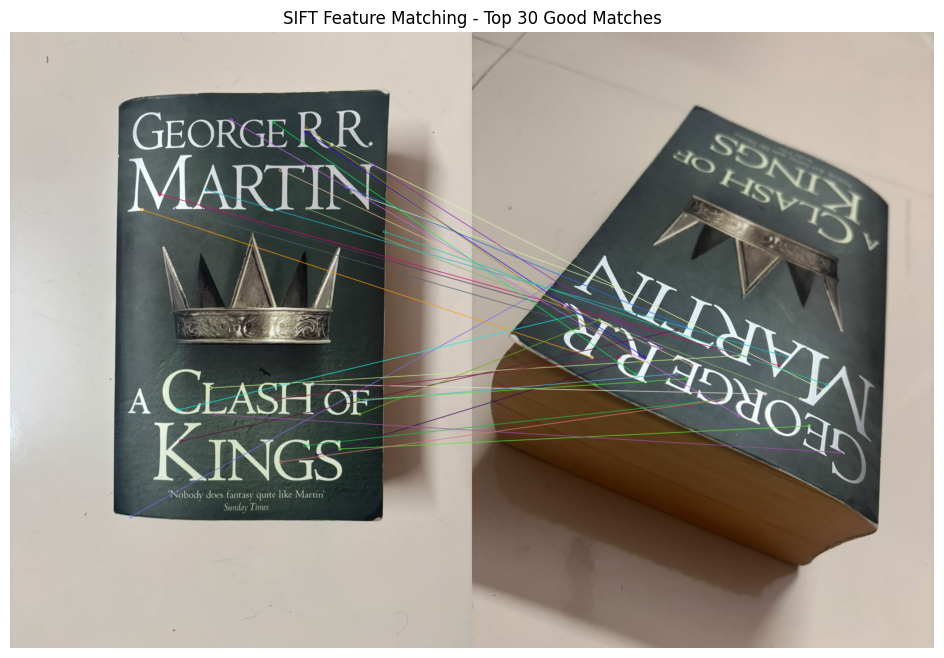

In [ ]:
# Select the 30 best SIFT matches
top_sift_matches = sift_good_matches[:30]

# Draw the top SIFT matches
sift_match_image = cv2.drawMatches(
    image1,
    sift_keypoints1,
    image2,
    sift_keypoints2,
    top_sift_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Convert BGR to RGB for Matplotlib
sift_match_image_rgb = cv2.cvtColor(
    sift_match_image,
    cv2.COLOR_BGR2RGB
)

# Display the matches
plt.figure(figsize=(18, 8))
plt.imshow(sift_match_image_rgb)
plt.title("SIFT Feature Matching - Top 30 Good Matches")
plt.axis("off")
plt.show()

## 4.4 ORB vs SIFT: Visual Comparison

Both ORB and SIFT have now been applied to Pair 1.

The following visualization places their top matches side by side.

This allows us to compare the visual quality of the correspondences produced by the two methods under a significant rotation and viewpoint change.

A match should ideally connect the same physical feature in both images. Therefore, visual inspection is important in addition to simply counting the number of matches.

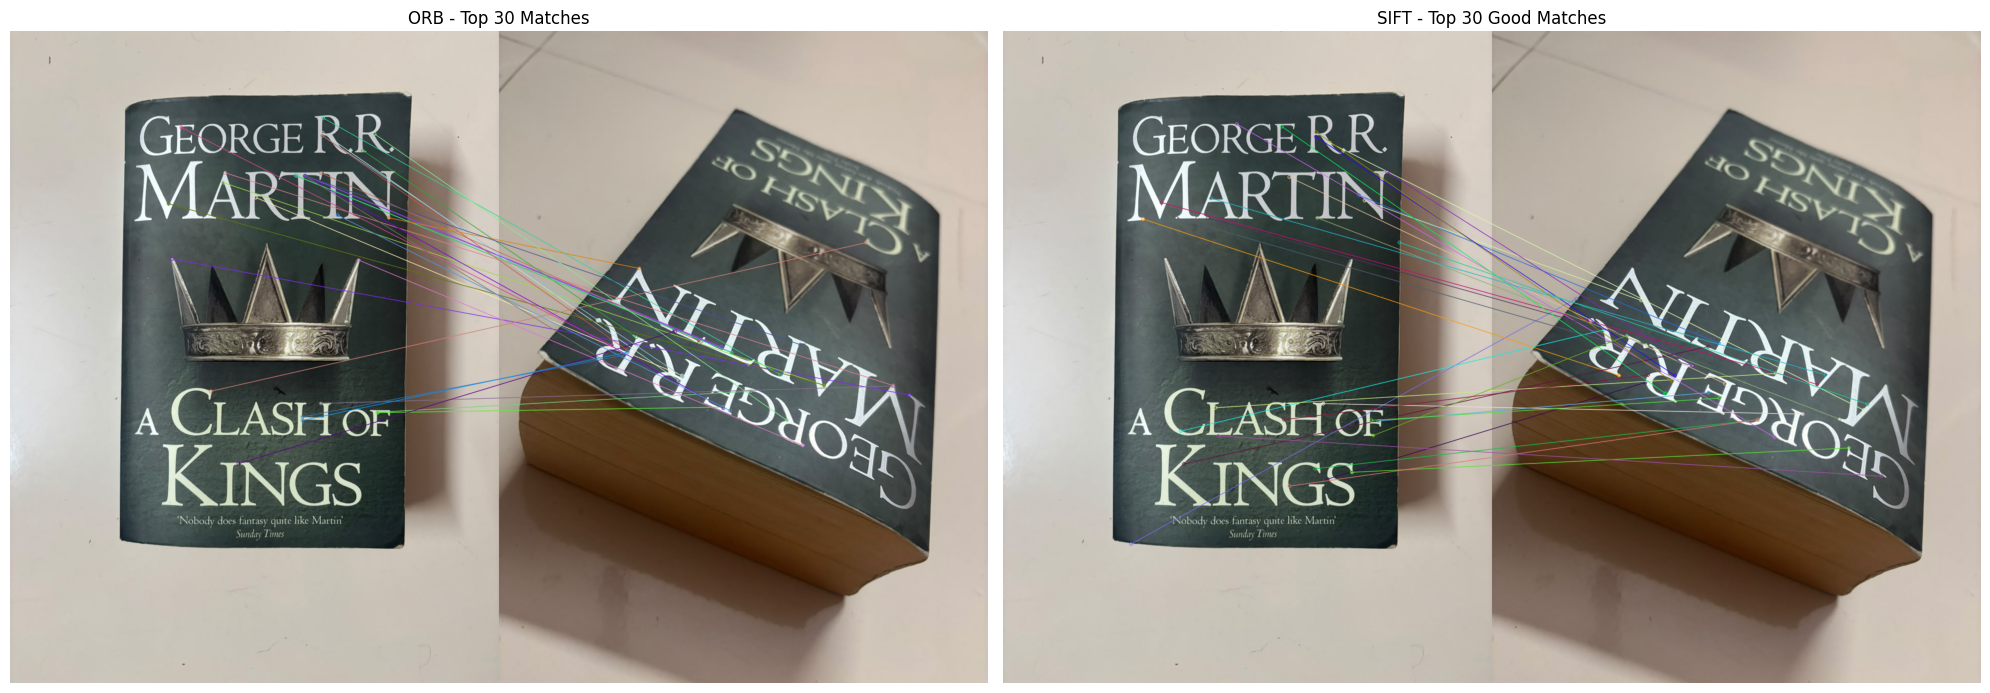

In [ ]:
# Display ORB and SIFT matching results side by side

plt.figure(figsize=(20, 8))

plt.subplot(1, 2, 1)
plt.imshow(orb_match_image_rgb)
plt.title("ORB - Top 30 Matches")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sift_match_image_rgb)
plt.title("SIFT - Top 30 Good Matches")
plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Preparing the Three Image Pairs

For the final comparison, we will test ORB and SIFT on three different image pairs.

Each pair represents a different change between the two photographs:

- **Pair 1:** Rotation + viewpoint change
- **Pair 2:** Rotation + cropping/scale change
- **Pair 3:** Lighting/brightness change

Using multiple conditions gives us a more meaningful comparison than testing the algorithms on only one pair.

Pair 1 has already been loaded. We will now upload the four images belonging to Pairs 2 and 3.

In [ ]:
from google.colab import files

# Upload the remaining four images:
# pair2.1.jpeg, pair2.2.jpeg, pair3.1.jpeg, pair3.2.jpeg
uploaded_remaining = files.upload()

print("\nUploaded files:")
for filename in uploaded_remaining.keys():
    print("-", filename)

Saving pair3.2.jpeg to pair3.2.jpeg
Saving pair3.1.jpeg to pair3.1.jpeg
Saving pair2.2.jpeg to pair2.2.jpeg
Saving pair2.1.jpeg to pair2.1.jpeg

Uploaded files:
- pair3.2.jpeg
- pair3.1.jpeg
- pair2.2.jpeg
- pair2.1.jpeg


## 5.1 Organizing the Image Pairs

We now have all six images uploaded to the Colab environment.

To avoid accidentally mixing images from different experiments, we explicitly group them into three pairs.

Each tuple contains:

`(Image 1 path, Image 2 path)`

The three pairs represent different conditions:

- **Pair 1:** Rotation + viewpoint change
- **Pair 2:** Rotation + cropping/scale change
- **Pair 3:** Lighting/brightness change

Keeping the pairs organized this way allows us to run exactly the same ORB and SIFT pipelines on every pair and compare their performance fairly.

In [ ]:
# Define the three image pairs

image_pairs = [
    {
        "name": "Pair 1",
        "condition": "Rotation + viewpoint change",
        "image1": "/content/pair1.1.jpeg",
        "image2": "/content/pair1.2.jpeg"
    },
    {
        "name": "Pair 2",
        "condition": "Rotation + cropping/scale change",
        "image1": "/content/pair2.1.jpeg",
        "image2": "/content/pair2.2.jpeg"
    },
    {
        "name": "Pair 3",
        "condition": "Lighting/brightness change",
        "image1": "/content/pair3.1.jpeg",
        "image2": "/content/pair3.2.jpeg"
    }
]

# Display the organized dataset
for pair in image_pairs:
    print(pair["name"])
    print(" Condition:", pair["condition"])
    print(" Image 1:", pair["image1"])
    print(" Image 2:", pair["image2"])
    print()

Pair 1
 Condition: Rotation + viewpoint change
 Image 1: /content/pair1.1.jpeg
 Image 2: /content/pair1.2.jpeg

Pair 2
 Condition: Rotation + cropping/scale change
 Image 1: /content/pair2.1.jpeg
 Image 2: /content/pair2.2.jpeg

Pair 3
 Condition: Lighting/brightness change
 Image 1: /content/pair3.1.jpeg
 Image 2: /content/pair3.2.jpeg



## 5.2 Creating the ORB and SIFT Pipelines for Comparison

We have already tested ORB and SIFT manually on Pair 1.

For the final experiment, we need to run the same process on all three image pairs. To keep the notebook clean, we define two simple functions.

The **ORB function** will:
1. Create an ORB detector.
2. Detect keypoints and compute binary descriptors.
3. Match the descriptors using BFMatcher with Hamming distance and `crossCheck=True`.
4. Sort the matches by distance.
5. Measure the total execution time.

The **SIFT function** will:
1. Create a SIFT detector.
2. Detect keypoints and compute floating-point descriptors.
3. Match descriptors using BFMatcher with L2 distance.
4. Find the two nearest matches for each descriptor.
5. Apply Lowe's ratio test with a ratio of 0.75.
6. Measure the total execution time.

The functions return the number of resulting matches and the processing time so that we can compare the methods across all three image pairs.

In [ ]:
def run_orb(image1, image2):
    # Start timing
    start_time = time.time()

    # Create ORB detector
    orb = cv2.ORB_create(nfeatures=1000)

    # Detect keypoints and compute descriptors
    keypoints1, descriptors1 = orb.detectAndCompute(image1, None)
    keypoints2, descriptors2 = orb.detectAndCompute(image2, None)

    # Create BFMatcher using Hamming distance
    matcher = cv2.BFMatcher(
        cv2.NORM_HAMMING,
        crossCheck=True
    )

    # Match descriptors
    matches = matcher.match(descriptors1, descriptors2)

    # Sort matches by increasing distance
    matches = sorted(
        matches,
        key=lambda match: match.distance
    )

    # End timing
    end_time = time.time()

    # Return number of matches and execution time
    return len(matches), end_time - start_time


def run_sift(image1, image2):
    # Start timing
    start_time = time.time()

    # Create SIFT detector
    sift = cv2.SIFT_create()

    # Detect keypoints and compute descriptors
    keypoints1, descriptors1 = sift.detectAndCompute(image1, None)
    keypoints2, descriptors2 = sift.detectAndCompute(image2, None)

    # Create BFMatcher using L2 distance
    matcher = cv2.BFMatcher(cv2.NORM_L2)

    # Find two nearest matches for every descriptor
    knn_matches = matcher.knnMatch(
        descriptors1,
        descriptors2,
        k=2
    )

    # Apply Lowe's ratio test
    ratio = 0.75
    good_matches = []

    for match_pair in knn_matches:
        if len(match_pair) == 2:
            best_match, second_best_match = match_pair

            if best_match.distance < ratio * second_best_match.distance:
                good_matches.append(best_match)

    # Sort good matches by increasing distance
    good_matches = sorted(
        good_matches,
        key=lambda match: match.distance
    )

    # End timing
    end_time = time.time()

    # Return number of good matches and execution time
    return len(good_matches), end_time - start_time

## 5.3 Running ORB and SIFT on All Three Image Pairs

We now run both feature-matching pipelines on all three image pairs.

For every pair, we record:

- **ORB matches** — matches obtained after ORB's cross-checking.
- **ORB execution time** — time required for the complete ORB pipeline.
- **SIFT good matches** — matches that passed Lowe's ratio test.
- **SIFT execution time** — time required for the complete SIFT pipeline.

The same algorithms and parameters are used for every pair so that the comparison is consistent.

The three pairs represent different image conditions:

- Pair 1: rotation + viewpoint change
- Pair 2: rotation + cropping/scale change
- Pair 3: lighting/brightness change

In [ ]:
# Store the comparison results
results = []

for pair in image_pairs:

    img1 = cv2.imread(pair["image1"])
    img2 = cv2.imread(pair["image2"])

    orb_matches, orb_time = run_orb(img1, img2)
    sift_matches, sift_time = run_sift(img1, img2)

    results.append({
        "Image Pair": pair["name"],
        "Condition": pair["condition"],
        "ORB Matches": orb_matches,
        "ORB Time (s)": round(orb_time, 3),
        "SIFT Good Matches": sift_matches,
        "SIFT Time (s)": round(sift_time, 3)
    })

results_df = pd.DataFrame(results)
results_df

,Image Pair,Condition,ORB Matches,ORB Time (s),SIFT Good Matches,SIFT Time (s)
0,Pair 1,Rotation + viewpoint change,274,0.071,279,0.719
1,Pair 2,Rotation + cropping/scale change,502,0.077,1493,1.870
2,Pair 3,Lighting/brightness change,439,0.123,520,1.304


## 5.4 Visual Comparison Across All Three Image Pairs

Numerical results alone do not fully describe feature-matching performance. Two methods may produce a similar number of matches while differing significantly in visual accuracy.

This section displays the **top 30 matches** produced by ORB and SIFT for each image pair.

By comparing the visual outputs, we can evaluate how well each method handles:

- Rotation and viewpoint changes (Pair 1)
- Rotation with cropping/scale changes (Pair 2)
- Lighting changes (Pair 3)

The same visualization method (`cv2.drawMatches`) is used for both algorithms, making the comparison consistent.

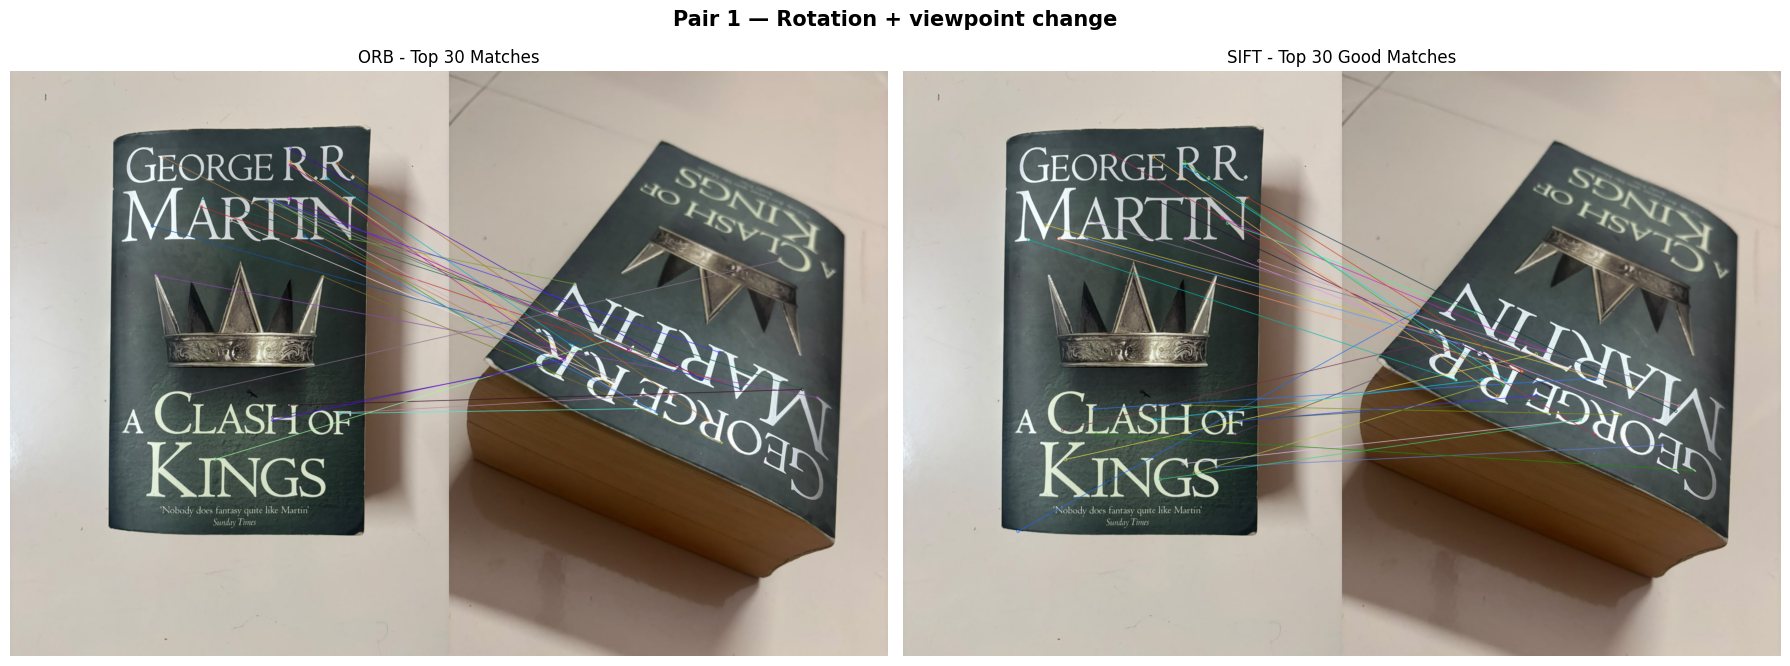

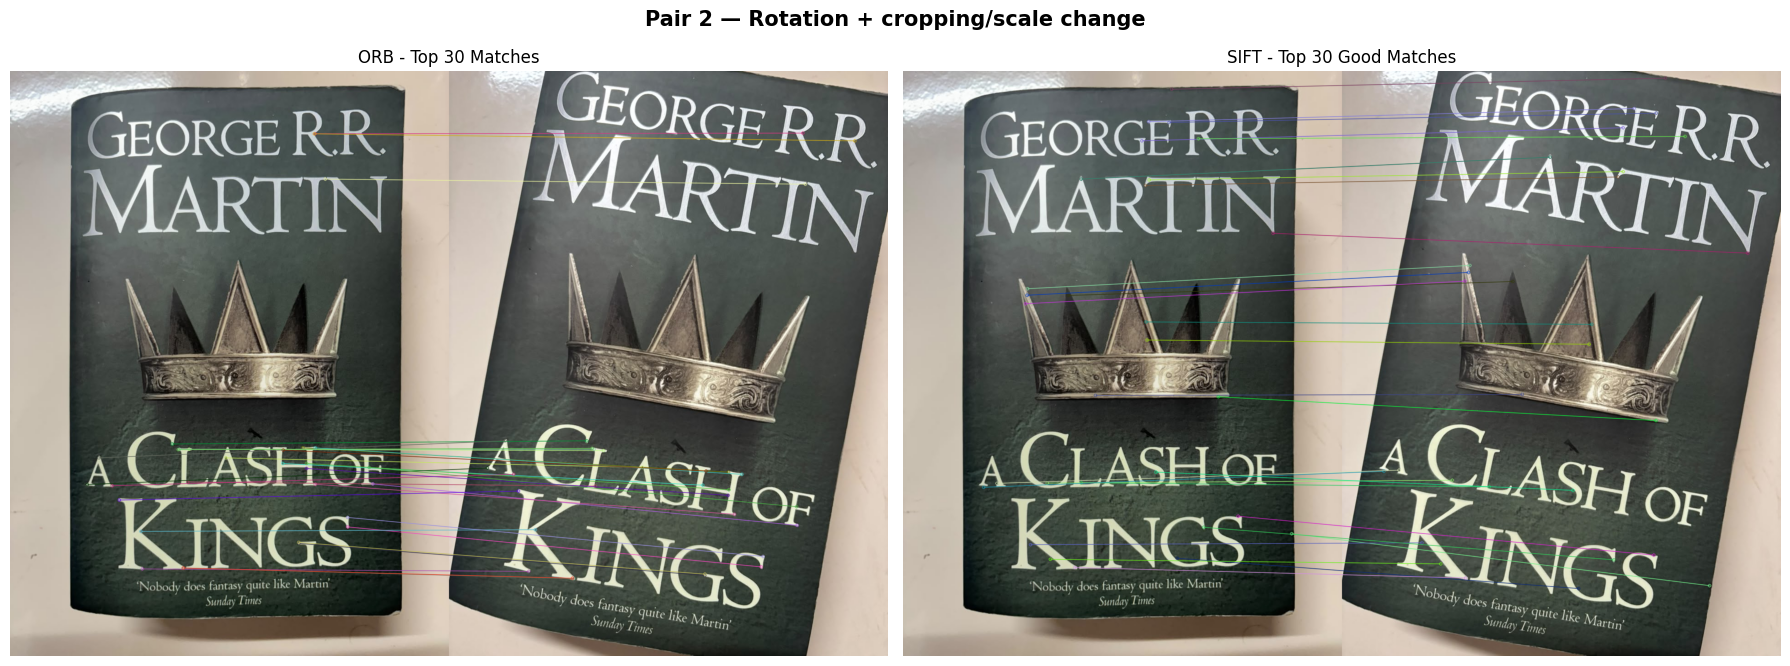

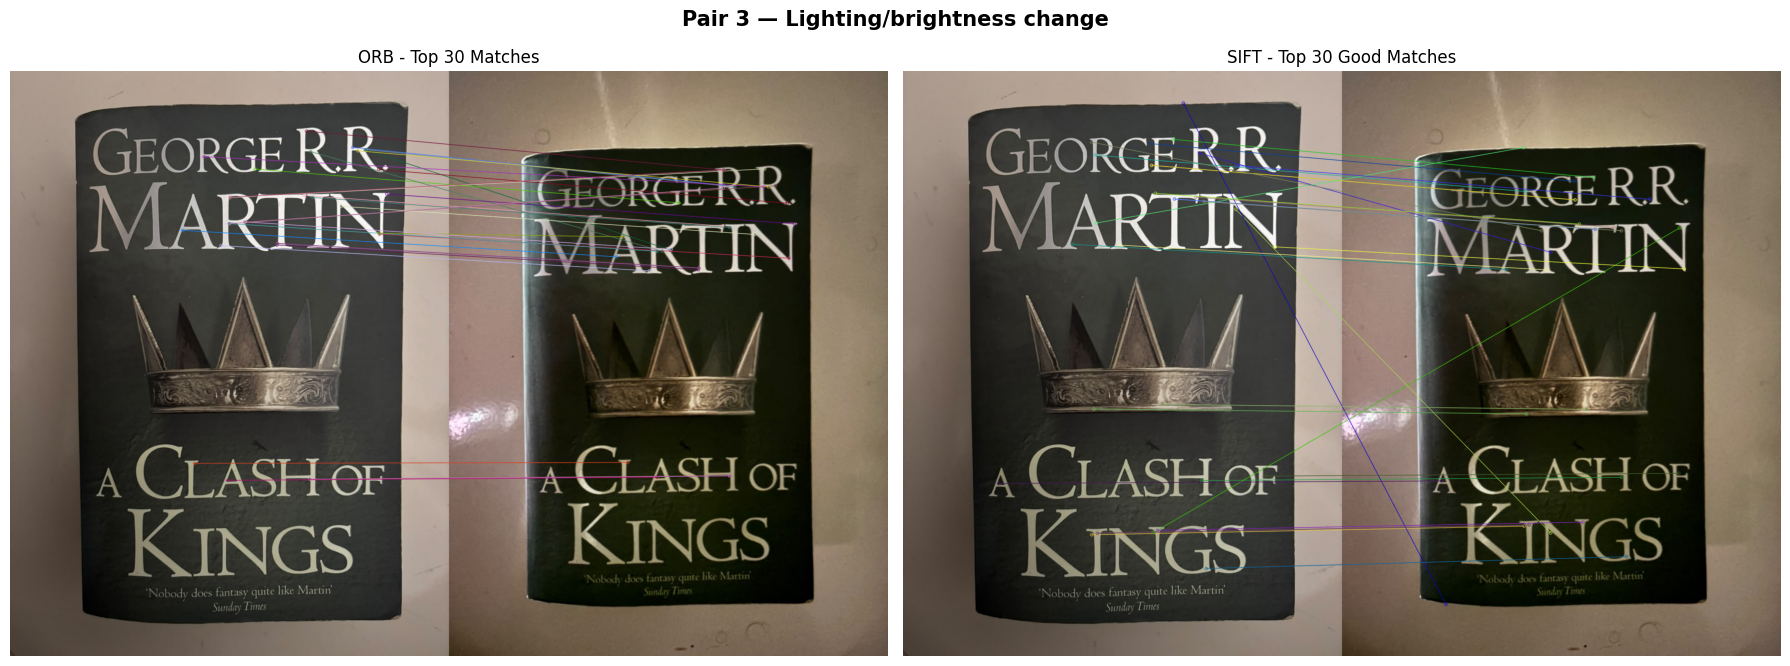

In [ ]:
def visualize_pair(image1, image2):
    # ---------- ORB ----------
    orb = cv2.ORB_create(nfeatures=1000)

    orb_kp1, orb_des1 = orb.detectAndCompute(image1, None)
    orb_kp2, orb_des2 = orb.detectAndCompute(image2, None)

    # BFMatcher with Hamming distance and cross-checking
    bf_orb = cv2.BFMatcher(
        cv2.NORM_HAMMING,
        crossCheck=True
    )

    orb_matches = bf_orb.match(orb_des1, orb_des2)

    # Sort by increasing Hamming distance
    orb_matches = sorted(
        orb_matches,
        key=lambda match: match.distance
    )

    # Keep top 30 matches
    orb_matches = orb_matches[:30]

    # Draw ORB matches
    orb_result = cv2.drawMatches(
        image1,
        orb_kp1,
        image2,
        orb_kp2,
        orb_matches,
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    # ---------- SIFT ----------
    sift = cv2.SIFT_create()

    sift_kp1, sift_des1 = sift.detectAndCompute(image1, None)
    sift_kp2, sift_des2 = sift.detectAndCompute(image2, None)

    # BFMatcher with L2 distance
    bf_sift = cv2.BFMatcher(cv2.NORM_L2)

    # Find two nearest neighbors for each descriptor
    knn_matches = bf_sift.knnMatch(
        sift_des1,
        sift_des2,
        k=2
    )

    # Apply Lowe's ratio test
    good_matches = []

    for match_pair in knn_matches:
        if len(match_pair) == 2:
            best_match, second_best_match = match_pair

            if best_match.distance < 0.75 * second_best_match.distance:
                good_matches.append(best_match)

    # Sort by increasing L2 distance
    good_matches = sorted(
        good_matches,
        key=lambda match: match.distance
    )

    # Keep top 30 good matches
    good_matches = good_matches[:30]

    # Draw SIFT matches
    sift_result = cv2.drawMatches(
        image1,
        sift_kp1,
        image2,
        sift_kp2,
        good_matches,
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    # Convert BGR to RGB for Matplotlib
    orb_result = cv2.cvtColor(
        orb_result,
        cv2.COLOR_BGR2RGB
    )

    sift_result = cv2.cvtColor(
        sift_result,
        cv2.COLOR_BGR2RGB
    )

    return orb_result, sift_result


# Display ORB and SIFT results for all three image pairs
for pair in image_pairs:

    img1 = cv2.imread(pair["image1"])
    img2 = cv2.imread(pair["image2"])

    orb_img, sift_img = visualize_pair(img1, img2)

    plt.figure(figsize=(18, 7))

    plt.suptitle(
        f"{pair['name']} — {pair['condition']}",
        fontsize=15,
        fontweight="bold"
    )

    plt.subplot(1, 2, 1)
    plt.imshow(orb_img)
    plt.title("ORB - Top 30 Matches")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(sift_img)
    plt.title("SIFT - Top 30 Good Matches")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

## 5.5 Observations and Analysis

The results show a clear difference between ORB and SIFT across the three image pairs.

### Pair 1 — Rotation + Viewpoint Change

ORB produced **274 matches**, while SIFT produced **279 good matches**.

The visual results show that both methods were able to identify corresponding regions despite the significant rotation and viewpoint change. However, some incorrect or geometrically inconsistent matches are still visible in both methods.

### Pair 2 — Rotation + Cropping/Scale Change

ORB produced **502 matches**, whereas SIFT produced **1493 good matches**.

SIFT produced substantially more matches for this pair, and its visual output contains many correspondences across the book. This suggests that SIFT handled the rotation and scale/cropping variation particularly well in this experiment.

### Pair 3 — Lighting/Brightness Change

ORB produced **439 matches**, while SIFT produced **520 good matches**.

Both methods were able to find corresponding features despite the lighting difference. SIFT produced more good matches, although the difference was much smaller than for Pair 2.

### Runtime Observation

ORB was consistently faster than SIFT across all three pairs.

The measured ORB execution times were approximately **0.07–0.08 seconds**, while SIFT required approximately **0.72–1.12 seconds**.

Therefore, the experiment demonstrates a practical trade-off:

- **ORB:** significantly faster and computationally efficient.
- **SIFT:** slower, but produced more good matches in all three test pairs.

The visual results should be considered together with the match counts because a higher number of matches does not automatically mean that every match is correct.

# 6. Conclusion

This project compared **ORB and SIFT feature matching** using BFMatcher on three different image pairs with changes in viewpoint, rotation, scale/cropping, and lighting.

The results showed that **ORB was consistently faster** than SIFT. ORB took approximately **0.07–0.08 seconds** for the tested image pairs, while SIFT took approximately **0.72–1.12 seconds**.

In terms of matching, **SIFT produced more good matches than ORB in all three experiments**. The difference was particularly large for Pair 2, which contained rotation and cropping/scale changes, where SIFT produced 1493 good matches compared with 502 ORB matches.

For Pair 1, the match counts were very similar (274 for ORB and 279 for SIFT), while for Pair 3, SIFT produced 520 good matches compared with 439 ORB matches.

Overall, our experiment demonstrates a trade-off between **speed and matching performance**:

- **ORB** is much faster and computationally efficient, making it suitable when processing speed is important.
- **SIFT** is slower but produced more good matches in our experiments and showed strong performance when the images had rotation, scale/cropping, and lighting differences.

Therefore, based on our test images, **SIFT provided stronger matching results, while ORB provided significantly faster processing**.

It is important to note that the number of matches alone does not determine which method is better. The visual quality and correctness of the correspondences should also be considered when evaluating feature-matching performance.

## 5.6 Final Results Summary

The table below summarizes the results obtained from all three image pairs.

For ORB, the reported match count represents matches obtained using **BFMatcher with Hamming distance and cross-checking**.

For SIFT, the reported match count represents matches that **passed Lowe's ratio test with a threshold of 0.75**.

The execution time includes feature detection, descriptor computation, and descriptor matching.

These results provide the quantitative basis for comparing the speed and matching performance of ORB and SIFT.

In [ ]:
# Create a copy of the results for the final summary
summary_df = results_df.copy()

# Calculate overall averages
average_orb_matches = summary_df["ORB Matches"].mean()
average_sift_matches = summary_df["SIFT Good Matches"].mean()

average_orb_time = summary_df["ORB Time (s)"].mean()
average_sift_time = summary_df["SIFT Time (s)"].mean()

# Display the results table
summary_df

,Image Pair,Condition,ORB Matches,ORB Time (s),SIFT Good Matches,SIFT Time (s)
0,Pair 1,Rotation + viewpoint change,274,0.071,279,0.719
1,Pair 2,Rotation + cropping/scale change,502,0.077,1493,1.870
2,Pair 3,Lighting/brightness change,439,0.123,520,1.304


In [ ]:
# Display overall average results

print("Average Results Across All Three Pairs")
print("-" * 45)

print(f"Average ORB matches:        {average_orb_matches:.1f}")
print(f"Average SIFT good matches:  {average_sift_matches:.1f}")

print(f"\nAverage ORB time:           {average_orb_time:.3f} seconds")
print(f"Average SIFT time:           {average_sift_time:.3f} seconds")

print(
    f"\nSIFT took approximately "
    f"{average_sift_time / average_orb_time:.1f}× "
    f"the average time of ORB."
)

Average Results Across All Three Pairs
---------------------------------------------
Average ORB matches:        405.0
Average SIFT good matches:  764.0

Average ORB time:           0.090 seconds
Average SIFT time:           1.298 seconds

SIFT took approximately 14.4× the average time of ORB.
